<a href="https://colab.research.google.com/github/Muqaddasjamil/Datarepo/blob/main/CS867_Assignment1_Image_Enhancement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CS867 Computer Vision — Assignment 1
## Medical Image Enhancement using Spatial, Fourier, and Hybrid Techniques

**Inputs:** `Chest.bmp` and `Skeleton.bmp`

This notebook implements the full computational workflow:

- **Part (a): Spatial-domain-only enhancement**
- **Part (b): Fourier-domain-only enhancement**
- **Part (c): Spatial–Fourier hybrid enhancement**
- **Part (d): Objective comparison using entropy, contrast, edge strength, histograms, and computation time**

It also saves enhanced images, spectra, comparison figures, parameter-sensitivity results, and CSV metric tables into an `output/` folder.

> Keep `Chest.bmp`, `Skeleton.bmp`, and this notebook in the same folder when running it on your own computer. The path helper also checks `/mnt/data` so the supplied files work in this prepared version.

## 1. Environment and imports

Required packages:

```bash
pip install opencv-python numpy pandas matplotlib scikit-image
```

The implementation uses vectorized NumPy operations and `numpy.fft` for frequency-domain processing.

In [ ]:
from pathlib import Path
import time
import warnings

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from skimage.measure import shannon_entropy
from skimage.filters import sobel

warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

OUT = Path("output")
OUT.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Output folder:", OUT.resolve())

OpenCV: 4.13.0
NumPy: 2.3.5
Output folder: /mnt/data/output


## 2. Load and inspect the input images

Both supplied files are read directly as 8-bit grayscale images. Basic statistics are printed first because the brightness distribution helps explain why the darker image may need a stronger gamma adjustment.

In [ ]:
def locate_file(filename):
    """Find an input file in common notebook locations."""
    candidates = [
        Path(filename),
        Path.cwd() / filename,
        Path("/mnt/data") / filename,
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError(
        f"{filename} was not found. Put it in the same folder as this notebook."
    )

def load_gray(filename):
    """Load one image as uint8 grayscale."""
    path = locate_file(filename)
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"OpenCV could not read {path}")
    return img, path

chest, chest_path = load_gray("Chest.bmp")
skeleton, skeleton_path = load_gray("Skeleton.bmp")

print("Chest:", chest_path, chest.shape, chest.dtype)
print("Skeleton:", skeleton_path, skeleton.shape, skeleton.dtype)

input_stats = pd.DataFrame([
    {
        "Image": "Chest",
        "Height": chest.shape[0],
        "Width": chest.shape[1],
        "Min": int(chest.min()),
        "Max": int(chest.max()),
        "Mean": float(chest.mean()),
        "Std": float(chest.std()),
        "P2": float(np.percentile(chest, 2)),
        "P98": float(np.percentile(chest, 98)),
    },
    {
        "Image": "Skeleton",
        "Height": skeleton.shape[0],
        "Width": skeleton.shape[1],
        "Min": int(skeleton.min()),
        "Max": int(skeleton.max()),
        "Mean": float(skeleton.mean()),
        "Std": float(skeleton.std()),
        "P2": float(np.percentile(skeleton, 2)),
        "P98": float(np.percentile(skeleton, 98)),
    }
])

display(input_stats.round(3))

Chest: Chest.bmp (484, 699) uint8
Skeleton: Skeleton.bmp (686, 471) uint8


,Image,Height,Width,Min,Max,Mean,Std,P2,P98
0,Chest,484,699,0,255,60.761,58.153,8.0,208.7
1,Skeleton,686,471,0,255,23.727,38.234,1.0,159.0


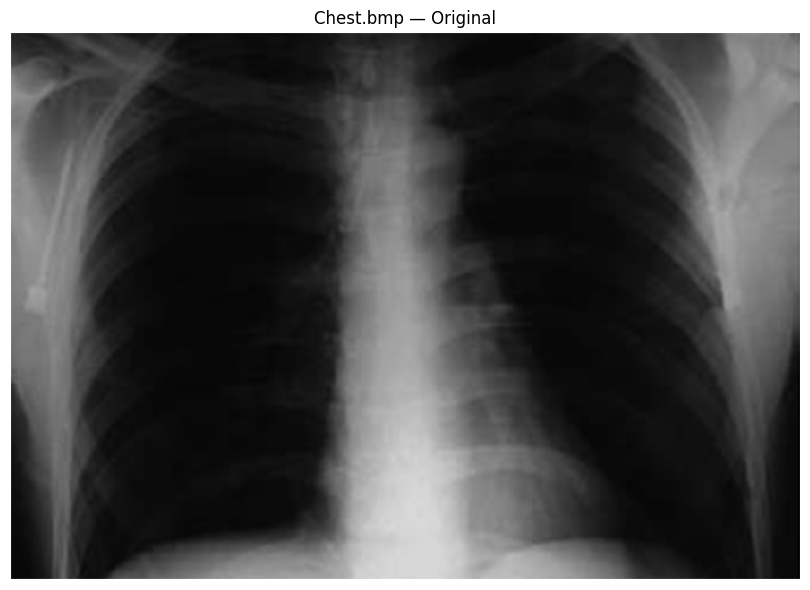

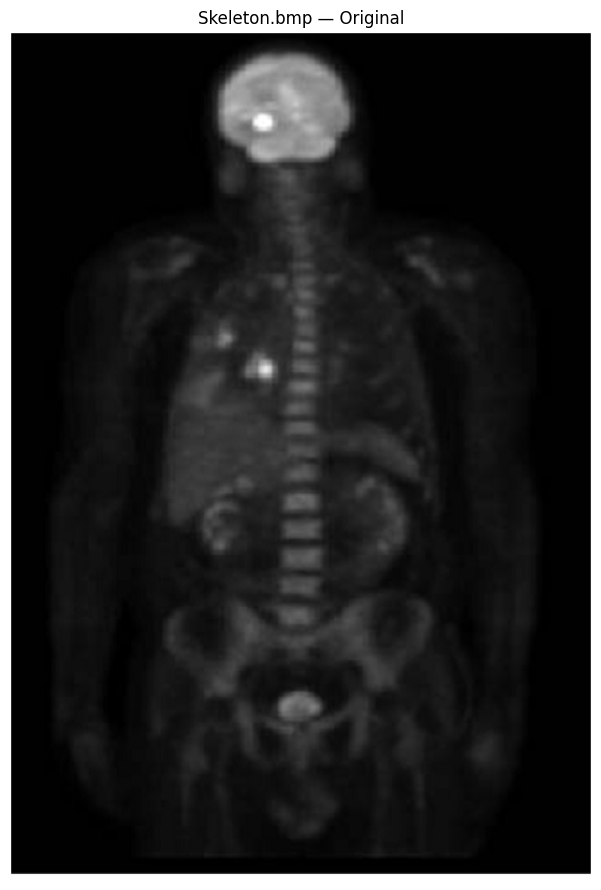

In [ ]:
plt.figure(figsize=(9, 6))
plt.imshow(chest, cmap="gray", vmin=0, vmax=255)
plt.title("Chest.bmp — Original")
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 9))
plt.imshow(skeleton, cmap="gray", vmin=0, vmax=255)
plt.title("Skeleton.bmp — Original")
plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Utility functions

Two normalizers are used. Standard min–max normalization is useful for general display, while percentile normalization is more robust after inverse FFT because a small number of extreme values can otherwise compress the visible intensity range.

In [ ]:
def normalize_uint8(img):
    """Min-max normalize any numeric array to uint8 [0, 255]."""
    x = np.asarray(img, dtype=np.float32)
    mn, mx = float(x.min()), float(x.max())
    if mx - mn < 1e-12:
        return np.zeros_like(x, dtype=np.uint8)
    y = (x - mn) / (mx - mn)
    return np.clip(y * 255.0, 0, 255).astype(np.uint8)

def robust_normalize_uint8(img, low_p=1.0, high_p=99.0):
    """Percentile normalize while reducing sensitivity to extreme outliers."""
    x = np.asarray(img, dtype=np.float32)
    lo, hi = np.percentile(x, [low_p, high_p])
    if hi - lo < 1e-12:
        return normalize_uint8(x)
    y = (x - lo) / (hi - lo)
    return np.clip(y * 255.0, 0, 255).astype(np.uint8)

def save_image(filename, img):
    """Save one image into the output folder."""
    path = OUT / filename
    cv2.imwrite(str(path), img)
    return path

def plot_histogram(img, title, filename=None):
    """Plot a standalone 256-bin grayscale histogram."""
    plt.figure(figsize=(7, 4))
    plt.hist(img.ravel(), bins=256, range=(0, 255))
    plt.title(title)
    plt.xlabel("Pixel intensity")
    plt.ylabel("Frequency")
    plt.tight_layout()
    if filename is not None:
        plt.savefig(OUT / filename, dpi=160, bbox_inches="tight")
    plt.show()

def plot_image_grid(items, title, filename=None, cols=4, figsize=(16, 10)):
    """Display a labeled grid of image results for visual comparison."""
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize)
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis("off")
    for ax, (label, img) in zip(axes, items):
        ax.imshow(img, cmap="gray")
        ax.set_title(label, fontsize=10)
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    if filename is not None:
        plt.savefig(OUT / filename, dpi=160, bbox_inches="tight")
    plt.show()

# Part (a) — Spatial-domain-only enhancement

The notebook implements:

1. Histogram equalization
2. CLAHE
3. Gamma correction
4. Percentile contrast stretching
5. Unsharp masking
6. Median denoising
7. A combined **spatial-only** pipeline: median → gamma → CLAHE → unsharp

No Fourier transform is used in this section.

In [ ]:
def histogram_equalization(img):
    """Global histogram equalization."""
    return cv2.equalizeHist(img)

def clahe_enhancement(img, clip_limit=2.0, tile_grid=(8, 8)):
    """Contrast Limited Adaptive Histogram Equalization."""
    clahe = cv2.createCLAHE(
        clipLimit=float(clip_limit),
        tileGridSize=tuple(tile_grid)
    )
    return clahe.apply(img)

def gamma_correction(img, gamma=0.7):
    """Gamma correction with a lookup table."""
    gamma = float(gamma)
    lut = np.array(
        [((i / 255.0) ** gamma) * 255.0 for i in range(256)],
        dtype=np.float32
    )
    return cv2.LUT(img, np.clip(lut, 0, 255).astype(np.uint8))

def contrast_stretch(img, low_p=2.0, high_p=98.0):
    """Percentile contrast stretching."""
    lo, hi = np.percentile(img, [low_p, high_p])
    if hi - lo < 1e-12:
        return img.copy()
    out = (img.astype(np.float32) - lo) / (hi - lo)
    return np.clip(out * 255.0, 0, 255).astype(np.uint8)

def unsharp_mask(img, sigma=1.5, amount=0.8):
    """Unsharp masking: (1+k)*image - k*GaussianBlur(image)."""
    blurred = cv2.GaussianBlur(img, (0, 0), sigmaX=float(sigma))
    return cv2.addWeighted(
        img, 1.0 + float(amount),
        blurred, -float(amount),
        0
    )

def median_denoise(img, ksize=3):
    """Median filter with a valid odd kernel size."""
    ksize = int(ksize)
    if ksize % 2 == 0:
        ksize += 1
    return cv2.medianBlur(img, ksize)

def spatial_pipeline(img, gamma=0.7, clip_limit=2.5,
                     sigma=1.2, amount=0.7):
    """Median -> gamma -> CLAHE -> unsharp, entirely in the spatial domain."""
    step1 = median_denoise(img, 3)
    step2 = gamma_correction(step1, gamma)
    step3 = clahe_enhancement(step2, clip_limit, (8, 8))
    step4 = unsharp_mask(step3, sigma, amount)
    return step4

# Part (b) — Fourier-domain-only enhancement

The 2-D FFT is shifted so that the DC component is centered. Smooth Gaussian and Butterworth transfer functions are used instead of ideal hard cutoffs to reduce ringing.

Implemented methods:

- Gaussian low-pass
- Gaussian high-pass
- Butterworth low-pass
- Butterworth high-pass
- High-frequency emphasis
- Homomorphic filtering
- Log-magnitude spectrum

Low-pass and high-pass images help demonstrate frequency behavior. High-frequency emphasis and homomorphic filtering are especially useful for actual visibility enhancement because they retain recognizable global structure.

In [ ]:
def distance_grid(shape):
    """Euclidean distance D(u,v) from the shifted Fourier center."""
    rows, cols = shape
    cy, cx = rows // 2, cols // 2
    y = np.arange(rows, dtype=np.float32) - cy
    x = np.arange(cols, dtype=np.float32) - cx
    Y, X = np.meshgrid(y, x, indexing="ij")
    return np.sqrt(X**2 + Y**2)

def gaussian_low_pass(shape, D0=30.0):
    D = distance_grid(shape)
    return np.exp(-(D**2) / (2.0 * float(D0)**2))

def gaussian_high_pass(shape, D0=30.0):
    return 1.0 - gaussian_low_pass(shape, D0)

def butterworth_low_pass(shape, D0=30.0, order=2):
    D = distance_grid(shape)
    D0 = float(D0)
    n = int(order)
    return 1.0 / (1.0 + (D / (D0 + 1e-12))**(2 * n))

def butterworth_high_pass(shape, D0=30.0, order=2):
    return 1.0 - butterworth_low_pass(shape, D0, order)

def high_frequency_emphasis_filter(shape, D0=30.0, a=1.0, b=1.0):
    """H(u,v) = a + b * GaussianHighPass(u,v)."""
    return float(a) + float(b) * gaussian_high_pass(shape, D0)

def apply_frequency_filter(img, H, robust=True):
    """Multiply shifted FFT by H and invert back to the spatial image."""
    F = np.fft.fft2(img.astype(np.float32))
    F_shift = np.fft.fftshift(F)
    G_shift = F_shift * H
    out = np.real(np.fft.ifft2(np.fft.ifftshift(G_shift)))
    if robust:
        return robust_normalize_uint8(out, 1, 99)
    return normalize_uint8(out)

def log_magnitude_spectrum(img):
    """Display-ready log magnitude of the shifted 2-D FFT."""
    F = np.fft.fft2(img.astype(np.float32))
    F_shift = np.fft.fftshift(F)
    mag = 20.0 * np.log1p(np.abs(F_shift))
    return normalize_uint8(mag)

def homomorphic_filter(img, D0=30.0, gamma_L=0.7,
                       gamma_H=1.5, c=1.0):
    """
    Homomorphic filtering in the log domain.
    Low frequencies model illumination; high frequencies carry more reflectance/detail.
    """
    x = img.astype(np.float32) / 255.0
    log_img = np.log1p(x)

    F = np.fft.fft2(log_img)
    F_shift = np.fft.fftshift(F)

    D2 = distance_grid(img.shape) ** 2
    H = (
        (float(gamma_H) - float(gamma_L)) *
        (1.0 - np.exp(-float(c) * D2 / (float(D0)**2))) +
        float(gamma_L)
    )

    G_shift = F_shift * H
    g = np.real(np.fft.ifft2(np.fft.ifftshift(G_shift)))
    out = np.expm1(g)
    return robust_normalize_uint8(out, 1, 99)

# Part (c) — Spatial–Fourier hybrid enhancement

Two approaches are included.

### Sequential hybrid
Homomorphic filtering → CLAHE → unsharp masking.

### Weighted fusion
\[
I_{hybrid} = \alpha I_{spatial} + (1-\alpha) I_{fourier}
\]

The notebook explicitly tests \(lpha = 0.3, 0.5, 0.7\).

In [ ]:
def hybrid_sequential(img, hom_params, clip_limit=2.5,
                      sigma=1.2, amount=0.6):
    """Fourier homomorphic -> spatial CLAHE -> spatial unsharp."""
    freq = homomorphic_filter(img, **hom_params)
    local = clahe_enhancement(freq, clip_limit, (8, 8))
    detail = unsharp_mask(local, sigma, amount)
    return detail

def weighted_fusion(spatial_img, fourier_img, alpha=0.5):
    """Weighted blend of spatial and Fourier enhancement outputs."""
    alpha = float(alpha)
    out = (
        alpha * spatial_img.astype(np.float32) +
        (1.0 - alpha) * fourier_img.astype(np.float32)
    )
    return np.clip(out, 0, 255).astype(np.uint8)

# Part (d) — Objective evaluation

Metrics:

- Shannon entropy
- Standard-deviation contrast
- RMS contrast
- Robust Michelson contrast using 1st and 99th percentiles
- Mean Sobel edge strength
- Mean intensity
- Computation time

A higher value is not automatically “better” for every metric. For example, edge strength can also increase when noise is amplified, so the metrics must be interpreted together with the images.

In [ ]:
def entropy_metric(img):
    return float(shannon_entropy(img))

def std_contrast(img):
    return float(np.std(img.astype(np.float32)))

def rms_contrast(img):
    x = img.astype(np.float32)
    mean = float(np.mean(x))
    if mean < 1e-12:
        return 0.0
    return float(np.std(x) / mean)

def michelson_contrast(img):
    lo, hi = np.percentile(img, [1, 99])
    if hi + lo < 1e-12:
        return 0.0
    return float((hi - lo) / (hi + lo))

def edge_strength(img):
    return float(np.mean(np.abs(sobel(img))))

def evaluate_metrics(img):
    return {
        "Entropy": entropy_metric(img),
        "StdContrast": std_contrast(img),
        "RMSContrast": rms_contrast(img),
        "Michelson": michelson_contrast(img),
        "EdgeStrength": edge_strength(img),
        "MeanIntensity": float(np.mean(img)),
    }

## 4. Transparent image-specific starting parameters

`Skeleton.bmp` is much darker than `Chest.bmp`, so the gamma setting is stronger for Skeleton. All parameters are kept in one dictionary so they can be changed and justified easily.

In [ ]:
PARAMS = {
    "Chest": {
        "gamma": 0.75,
        "clahe_clip": 2.0,
        "unsharp_sigma": 1.2,
        "unsharp_amount": 0.7,
        "D0": 30.0,
        "butter_order": 2,
        "hfe_a": 1.0,
        "hfe_b": 1.0,
        "homomorphic": {
            "D0": 30.0,
            "gamma_L": 0.7,
            "gamma_H": 1.5,
            "c": 1.0,
        },
    },
    "Skeleton": {
        "gamma": 0.50,
        "clahe_clip": 2.5,
        "unsharp_sigma": 1.2,
        "unsharp_amount": 0.7,
        "D0": 30.0,
        "butter_order": 2,
        "hfe_a": 1.0,
        "hfe_b": 1.0,
        "homomorphic": {
            "D0": 40.0,
            "gamma_L": 0.9,
            "gamma_H": 1.4,
            "c": 1.0,
        },
    },
}

display(pd.DataFrame(PARAMS).T)

,gamma,clahe_clip,unsharp_sigma,unsharp_amount,D0,butter_order,hfe_a,hfe_b,homomorphic
Chest,0.75,2.0,1.2,0.7,30.0,2,1.0,1.0,"{'D0': 30.0, 'gamma_L': 0.7, 'gamma_H': 1.5, '..."
Skeleton,0.5,2.5,1.2,0.7,30.0,2,1.0,1.0,"{'D0': 40.0, 'gamma_L': 0.9, 'gamma_H': 1.4, '..."


## 5. Run every required method and record time

In [ ]:
def timed_call(func, *args, **kwargs):
    start = time.perf_counter()
    out = func(*args, **kwargs)
    return out, time.perf_counter() - start

def run_all_methods(name, img):
    p = PARAMS[name]
    results = {"Original": img.copy()}
    times = {"Original": 0.0}

    # Spatial only
    results["HistEq"], times["HistEq"] = timed_call(histogram_equalization, img)
    results["CLAHE"], times["CLAHE"] = timed_call(
        clahe_enhancement, img, p["clahe_clip"], (8, 8)
    )
    results["Gamma"], times["Gamma"] = timed_call(
        gamma_correction, img, p["gamma"]
    )
    results["ContrastStretch"], times["ContrastStretch"] = timed_call(
        contrast_stretch, img, 2, 98
    )
    results["Unsharp"], times["Unsharp"] = timed_call(
        unsharp_mask, img, p["unsharp_sigma"], p["unsharp_amount"]
    )
    results["SpatialBest"], times["SpatialBest"] = timed_call(
        spatial_pipeline,
        img,
        p["gamma"],
        p["clahe_clip"],
        p["unsharp_sigma"],
        p["unsharp_amount"],
    )

    # Fourier only
    D0 = p["D0"]
    n = p["butter_order"]

    results["GaussianLP"], times["GaussianLP"] = timed_call(
        apply_frequency_filter, img, gaussian_low_pass(img.shape, D0)
    )
    results["GaussianHP"], times["GaussianHP"] = timed_call(
        apply_frequency_filter, img, gaussian_high_pass(img.shape, D0)
    )
    results["ButterworthLP"], times["ButterworthLP"] = timed_call(
        apply_frequency_filter, img, butterworth_low_pass(img.shape, D0, n)
    )
    results["ButterworthHP"], times["ButterworthHP"] = timed_call(
        apply_frequency_filter, img, butterworth_high_pass(img.shape, D0, n)
    )

    hfe_mask = high_frequency_emphasis_filter(
        img.shape, D0, p["hfe_a"], p["hfe_b"]
    )
    results["HighFreqEmphasis"], times["HighFreqEmphasis"] = timed_call(
        apply_frequency_filter, img, hfe_mask
    )
    results["Homomorphic"], times["Homomorphic"] = timed_call(
        homomorphic_filter, img, **p["homomorphic"]
    )

    # Hybrid
    results["HybridSequential"], times["HybridSequential"] = timed_call(
        hybrid_sequential,
        img,
        p["homomorphic"],
        p["clahe_clip"],
        p["unsharp_sigma"],
        0.6,
    )

    for alpha in (0.3, 0.5, 0.7):
        key = f"HybridFusion_a{alpha:.1f}"
        results[key], times[key] = timed_call(
            weighted_fusion,
            results["SpatialBest"],
            results["HighFreqEmphasis"],
            alpha,
        )

    rows = []
    for method, out in results.items():
        rows.append({
            "Image": name,
            "Method": method,
            **evaluate_metrics(out),
            "TimeSeconds": times[method],
        })

    return results, pd.DataFrame(rows)

all_results = {}
tables = []

for image_name, img in [("Chest", chest), ("Skeleton", skeleton)]:
    result_dict, metric_table = run_all_methods(image_name, img)
    all_results[image_name] = result_dict
    tables.append(metric_table)

metrics_df = pd.concat(tables, ignore_index=True)
display(metrics_df.round(5))

,Image,Method,Entropy,StdContrast,RMSContrast,Michelson,EdgeStrength,MeanIntensity,TimeSeconds
0,Chest,Original,6.81691,58.15268,0.95707,0.92825,0.01482,60.76109,0.00000
1,Chest,HistEq,6.59200,71.46131,0.55076,0.87407,0.01868,129.74999,0.00087
2,Chest,CLAHE,7.39075,67.56606,0.84280,0.92683,0.02035,80.16823,0.00037
3,Chest,Gamma,6.75349,60.23064,0.75942,0.84362,0.01492,79.31187,0.00016
4,Chest,ContrastStretch,6.71711,72.44835,1.09601,1.00000,0.01643,66.10189,0.00205
5,Chest,Unsharp,6.84065,58.19385,0.96103,0.93694,0.01670,60.55346,0.00046
6,Chest,SpatialBest,7.45703,67.26369,0.74885,0.88189,0.02197,89.82217,0.00103
7,Chest,GaussianLP,7.11131,70.19844,1.06410,1.00000,0.01001,65.96991,0.01955
8,Chest,GaussianHP,5.62670,28.03733,0.14621,1.00000,0.03720,191.75654,0.02084
9,Chest,ButterworthLP,7.11150,70.18929,1.06478,1.00000,0.00992,65.91881,0.01878


## 6. Save processed images and metric tables

In [ ]:
for image_name, results in all_results.items():
    for method, img in results.items():
        safe_method = method.replace(".", "p")
        save_image(f"{image_name}_{safe_method}.png", img)

metrics_df.to_csv(OUT / "all_metrics.csv", index=False)
metrics_df[metrics_df["Image"] == "Chest"].to_csv(
    OUT / "Chest_metrics.csv", index=False
)
metrics_df[metrics_df["Image"] == "Skeleton"].to_csv(
    OUT / "Skeleton_metrics.csv", index=False
)

print("Saved outputs to:", OUT.resolve())

Saved outputs to: /mnt/data/output


## 7. Spatial-domain visual comparison

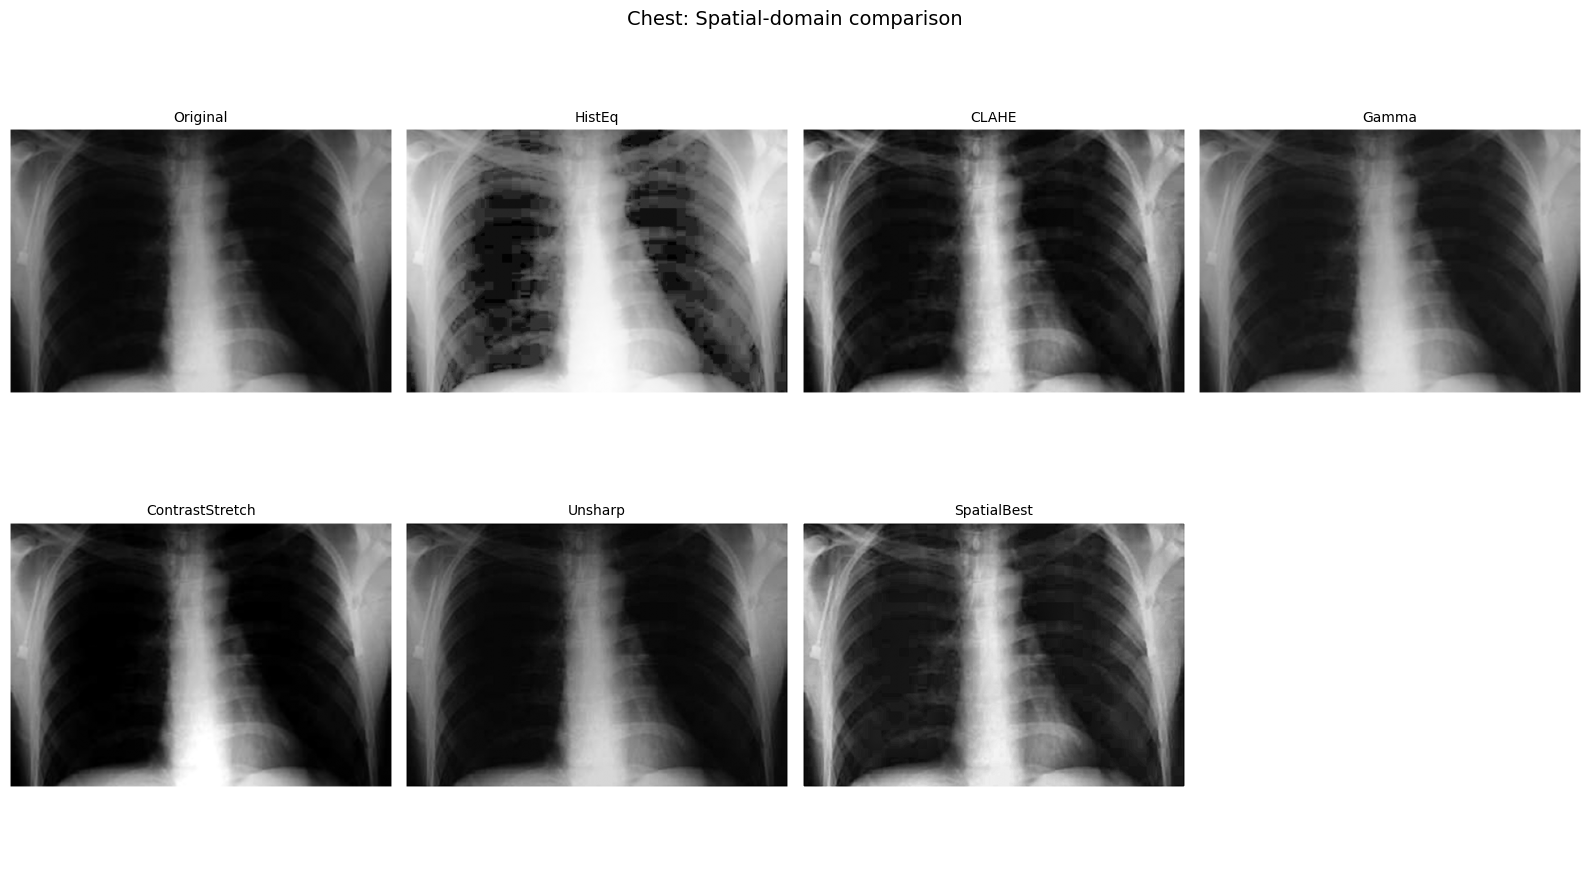

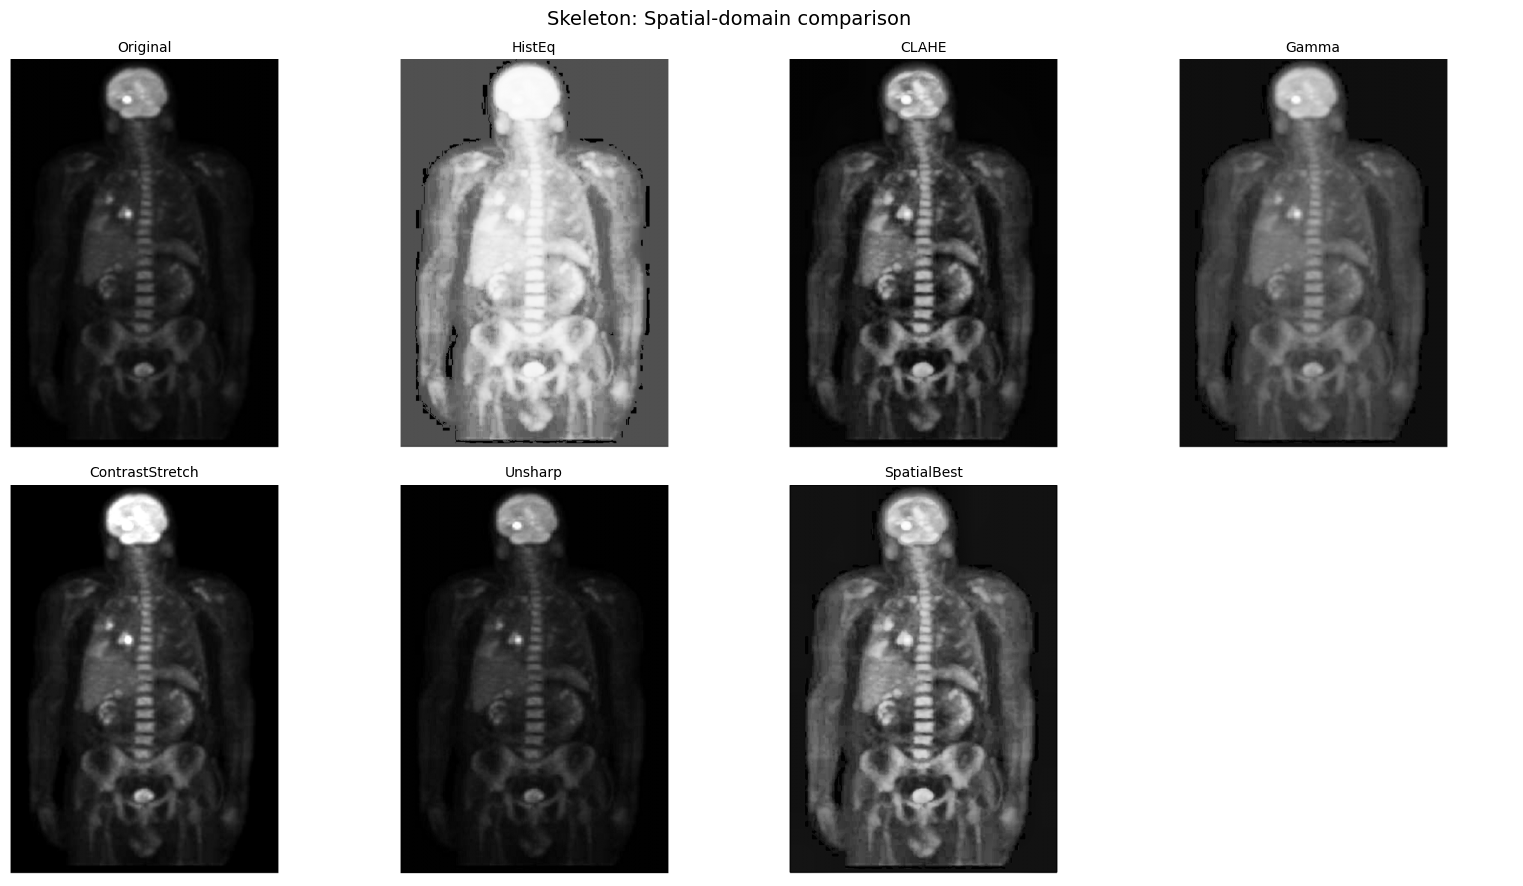

In [ ]:
spatial_keys = [
    "Original", "HistEq", "CLAHE", "Gamma",
    "ContrastStretch", "Unsharp", "SpatialBest"
]

for image_name in ("Chest", "Skeleton"):
    items = [(k, all_results[image_name][k]) for k in spatial_keys]
    plot_image_grid(
        items,
        f"{image_name}: Spatial-domain comparison",
        f"{image_name}_spatial_comparison.png",
        cols=4,
        figsize=(16, 9),
    )

## 8. Fourier-domain visual comparison

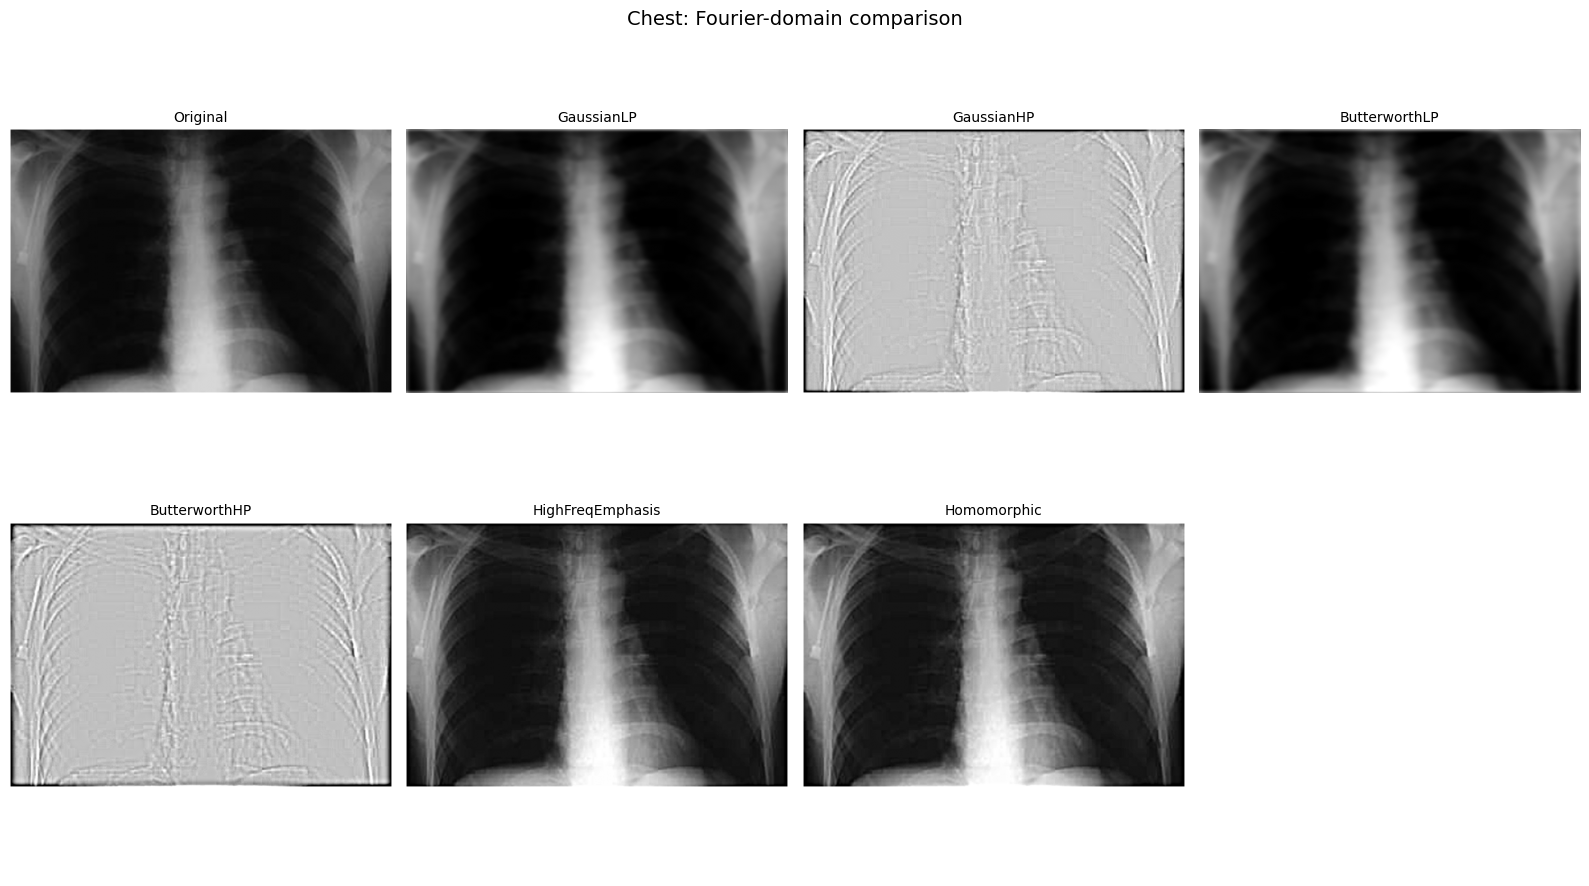

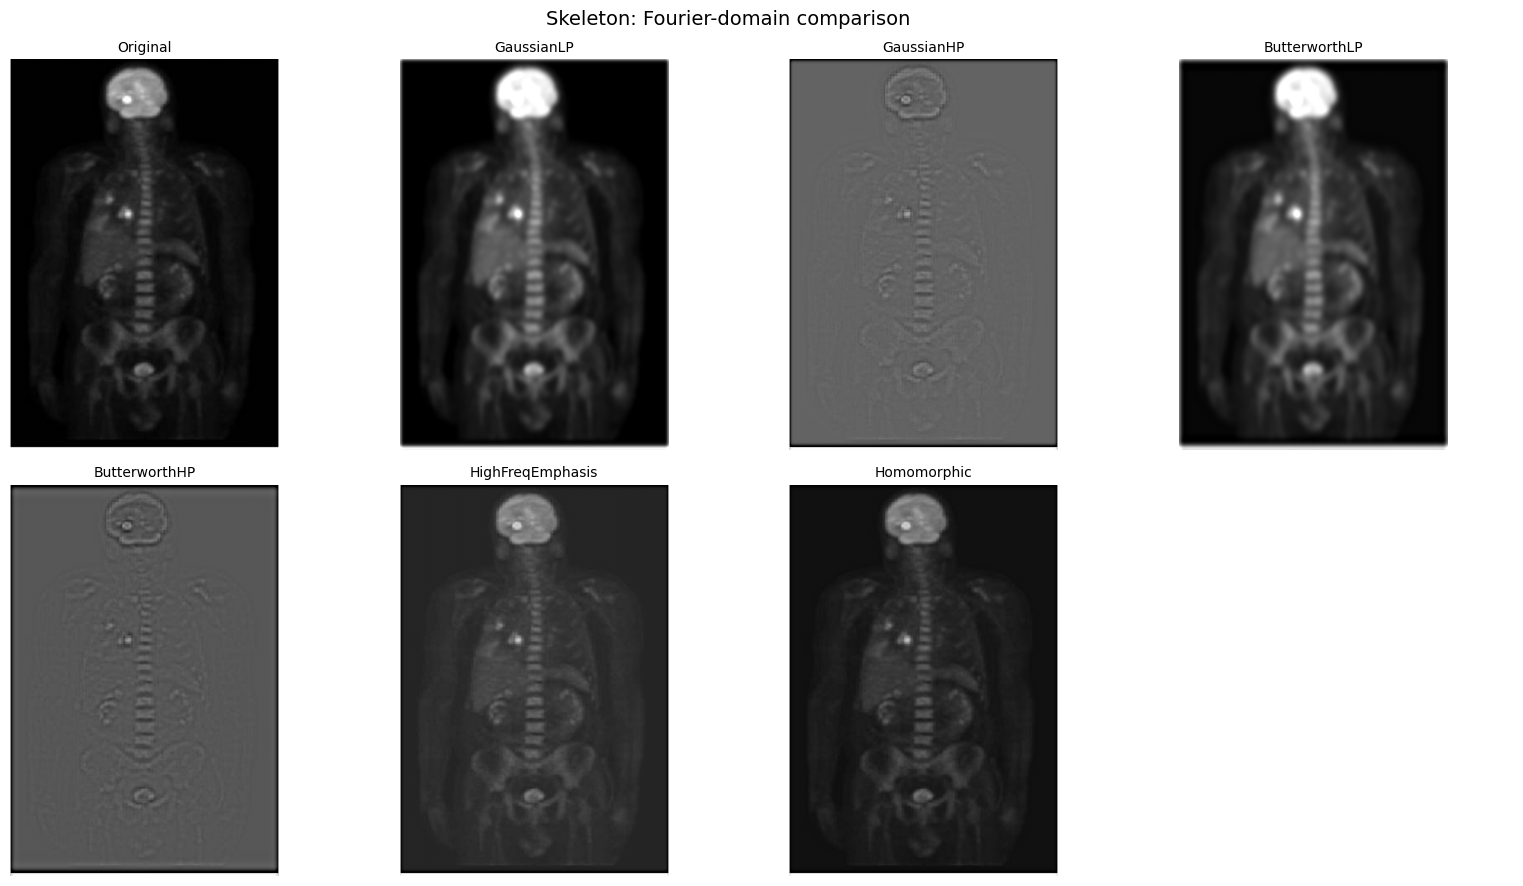

In [ ]:
fourier_keys = [
    "Original", "GaussianLP", "GaussianHP",
    "ButterworthLP", "ButterworthHP",
    "HighFreqEmphasis", "Homomorphic"
]

for image_name in ("Chest", "Skeleton"):
    items = [(k, all_results[image_name][k]) for k in fourier_keys]
    plot_image_grid(
        items,
        f"{image_name}: Fourier-domain comparison",
        f"{image_name}_fourier_comparison.png",
        cols=4,
        figsize=(16, 9),
    )

## 9. Original log-magnitude spectra

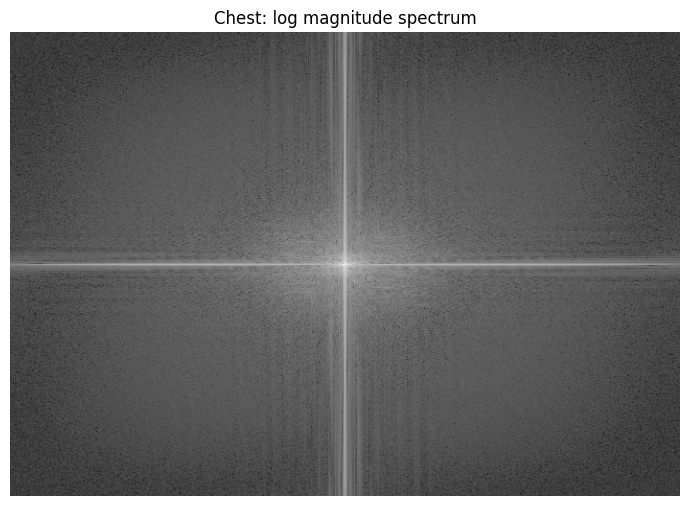

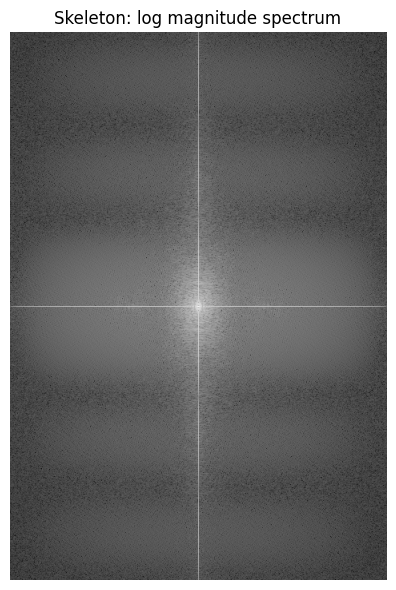

In [ ]:
for image_name, img in [("Chest", chest), ("Skeleton", skeleton)]:
    spectrum = log_magnitude_spectrum(img)
    save_image(f"{image_name}_log_magnitude_spectrum.png", spectrum)

    plt.figure(figsize=(7, 6))
    plt.imshow(spectrum, cmap="gray")
    plt.title(f"{image_name}: log magnitude spectrum")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

## 10. Spatial vs Fourier vs Hybrid comparison

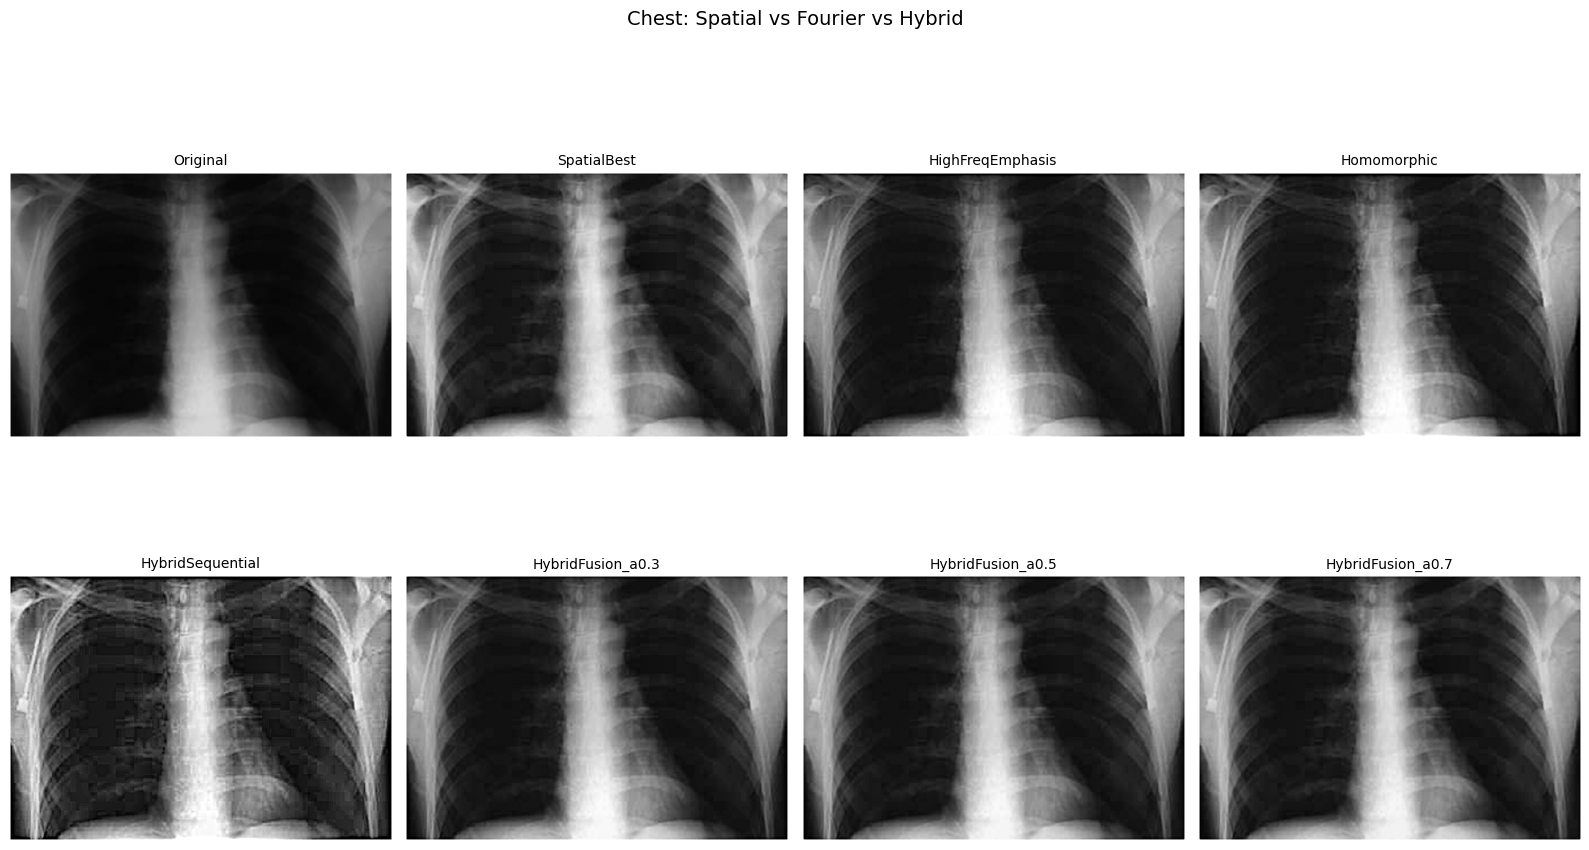

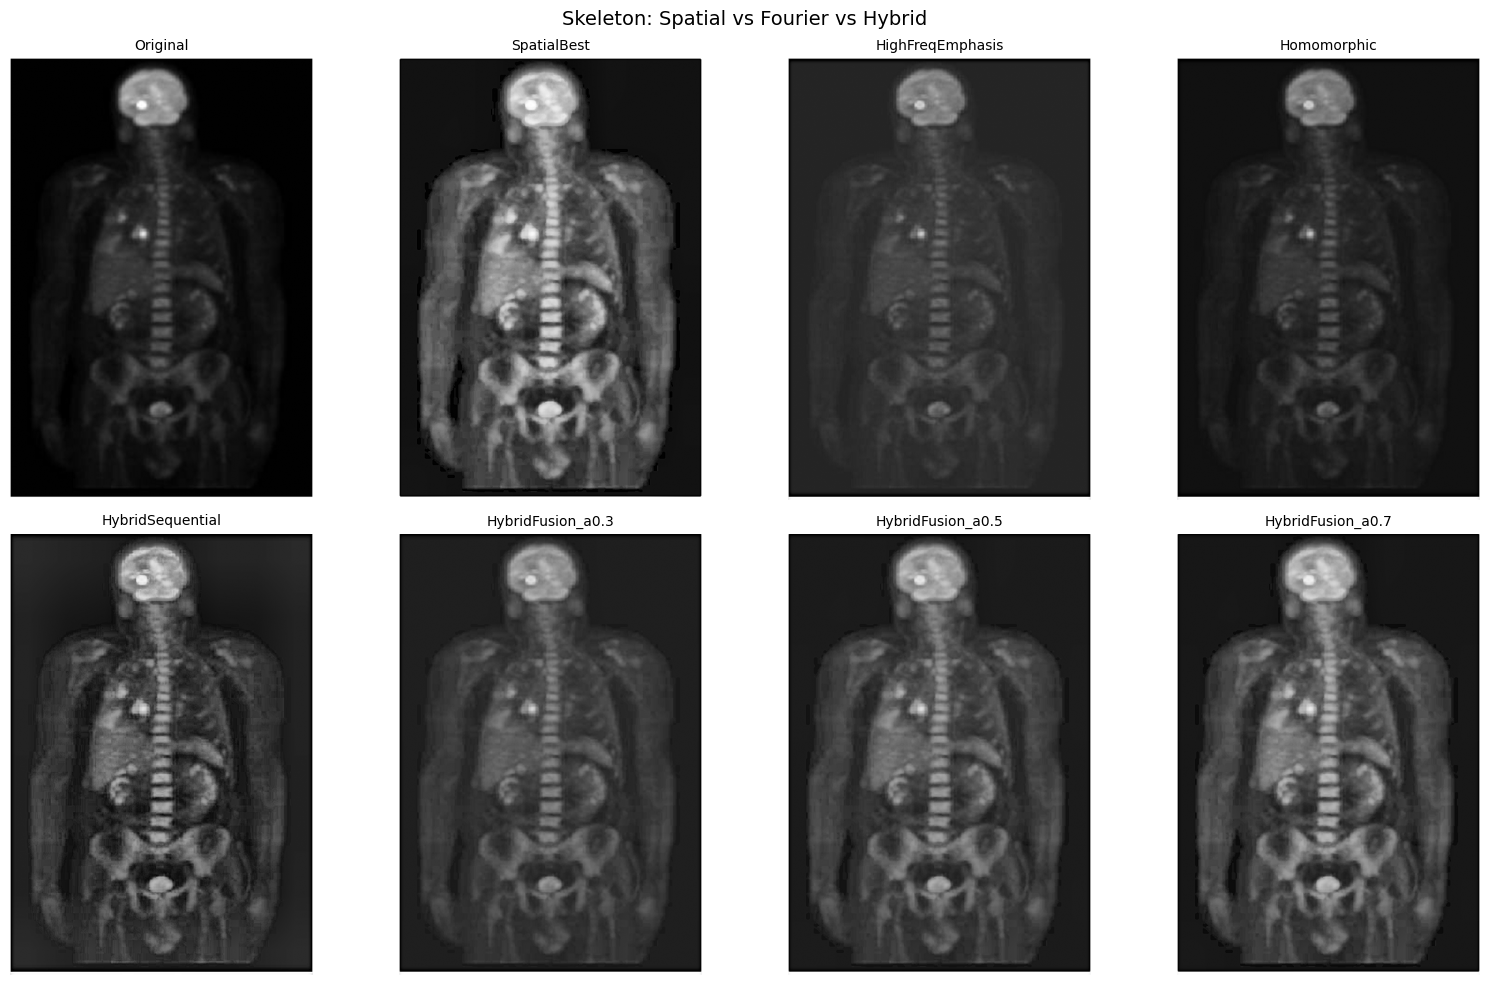

In [ ]:
hybrid_keys = [
    "Original",
    "SpatialBest",
    "HighFreqEmphasis",
    "Homomorphic",
    "HybridSequential",
    "HybridFusion_a0.3",
    "HybridFusion_a0.5",
    "HybridFusion_a0.7",
]

for image_name in ("Chest", "Skeleton"):
    items = [(k, all_results[image_name][k]) for k in hybrid_keys]
    plot_image_grid(
        items,
        f"{image_name}: Spatial vs Fourier vs Hybrid",
        f"{image_name}_hybrid_comparison.png",
        cols=4,
        figsize=(16, 10),
    )

## 11. Histograms for main outputs

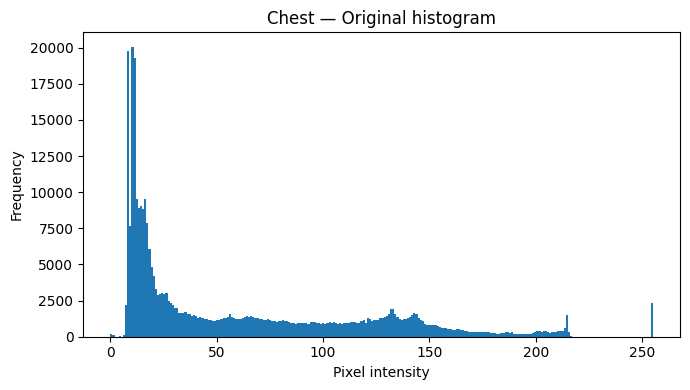

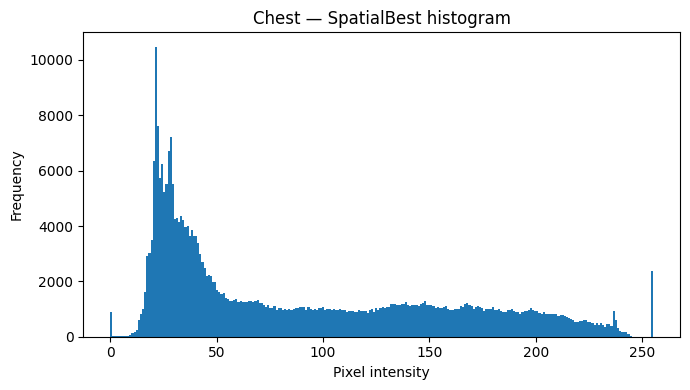

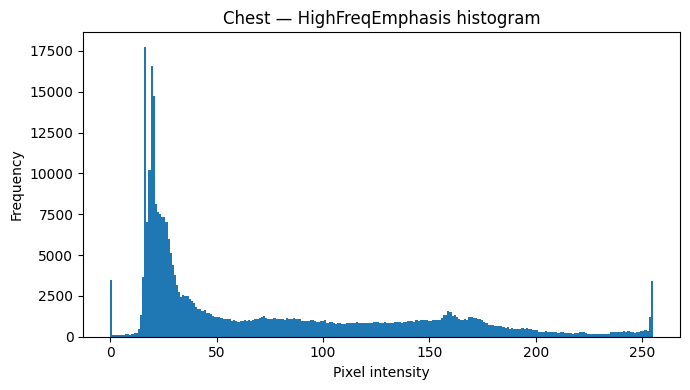

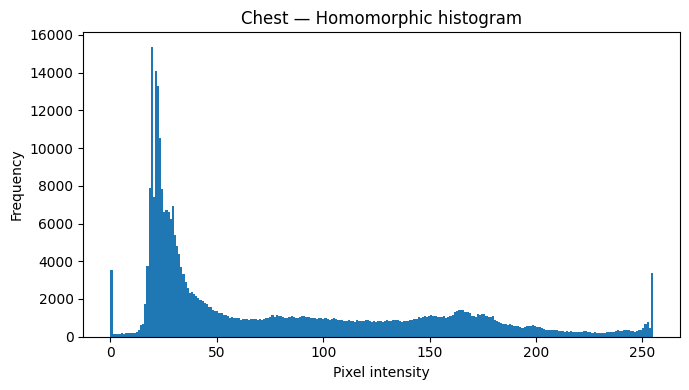

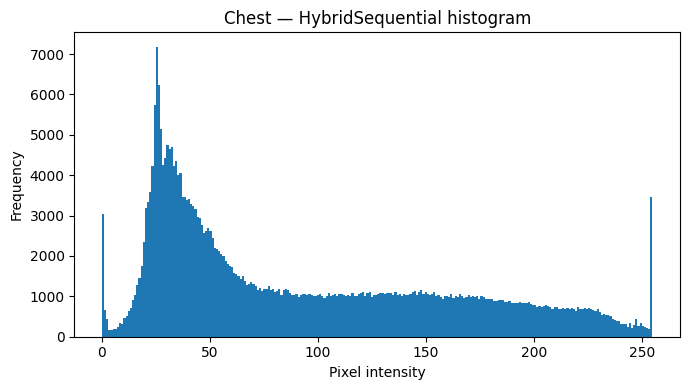

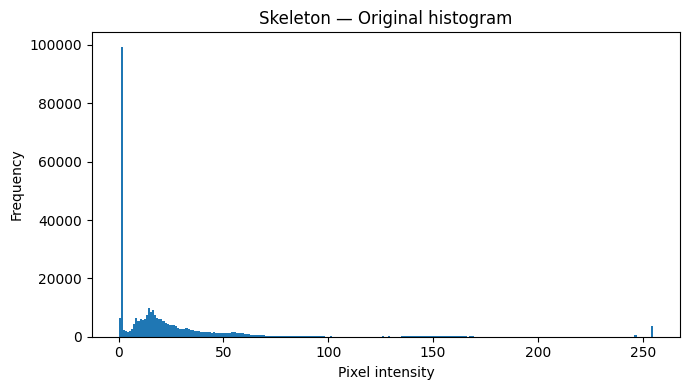

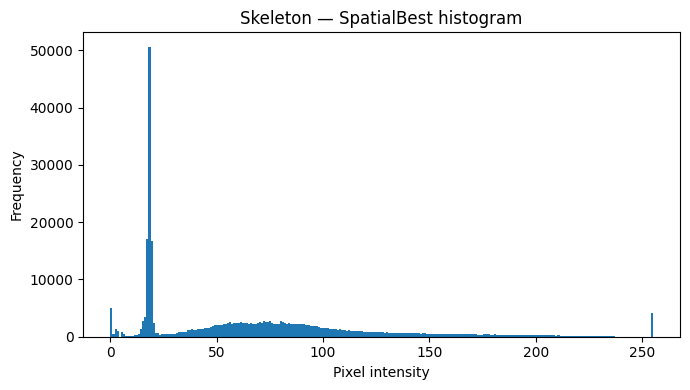

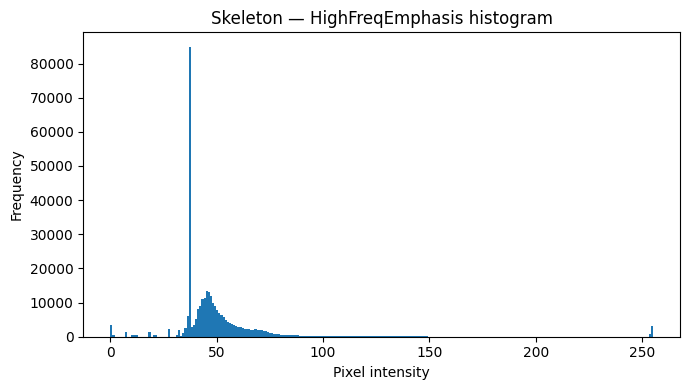

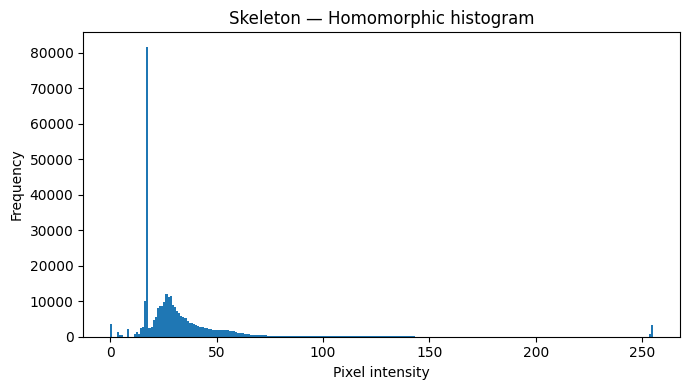

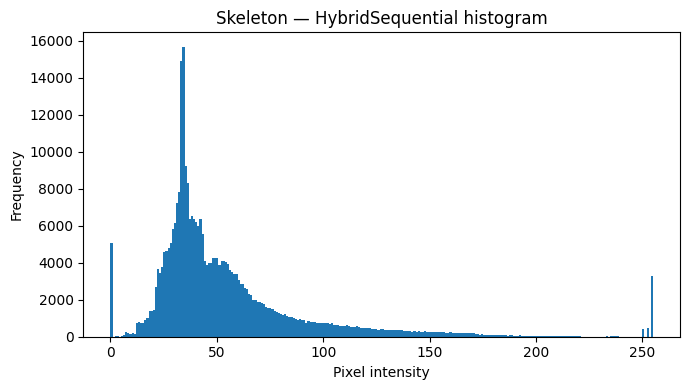

In [ ]:
main_hist_keys = [
    "Original",
    "SpatialBest",
    "HighFreqEmphasis",
    "Homomorphic",
    "HybridSequential",
]

for image_name in ("Chest", "Skeleton"):
    for method in main_hist_keys:
        plot_histogram(
            all_results[image_name][method],
            f"{image_name} — {method} histogram",
            f"{image_name}_{method}_histogram.png",
        )

## 12. Compact tables for the later report

In [ ]:
core_methods = [
    "Original",
    "SpatialBest",
    "HighFreqEmphasis",
    "Homomorphic",
    "HybridSequential",
    "HybridFusion_a0.3",
    "HybridFusion_a0.5",
    "HybridFusion_a0.7",
]

core_metrics = metrics_df[metrics_df["Method"].isin(core_methods)].copy()

for image_name in ("Chest", "Skeleton"):
    print("\n" + "=" * 70)
    print(image_name, "— core metrics")
    print("=" * 70)
    display(
        core_metrics[core_metrics["Image"] == image_name]
        .drop(columns="Image")
        .round(5)
        .reset_index(drop=True)
    )


Chest — core metrics


,Method,Entropy,StdContrast,RMSContrast,Michelson,EdgeStrength,MeanIntensity,TimeSeconds
0,Original,6.81691,58.15268,0.95707,0.92825,0.01482,60.76109,0.00000
1,SpatialBest,7.45703,67.26369,0.74885,0.88189,0.02197,89.82217,0.00103
2,HighFreqEmphasis,7.08404,66.42361,0.87613,1.00000,0.02055,75.81505,0.01999
3,Homomorphic,7.17061,67.31972,0.84451,1.00000,0.02164,79.71470,0.02297
4,HybridSequential,7.62379,68.55445,0.73586,0.99219,0.03673,93.16201,0.02676
5,HybridFusion_a0.3,7.24970,66.15844,0.83147,0.91538,0.02078,79.56795,0.00089
6,HybridFusion_a0.5,7.32064,66.22100,0.80200,0.89961,0.02100,82.56991,0.00024
7,HybridFusion_a0.7,7.37956,66.49521,0.78073,0.89105,0.02134,85.17077,0.00025



Skeleton — core metrics


,Method,Entropy,StdContrast,RMSContrast,Michelson,EdgeStrength,MeanIntensity,TimeSeconds
0,Original,5.14867,38.23372,1.61143,1.00000,0.01705,23.72654,0.00000
1,SpatialBest,6.63023,54.39284,0.78597,1.00000,0.03043,69.20437,0.00103
2,HighFreqEmphasis,5.06899,29.92825,0.58895,1.00000,0.01769,50.81597,0.01436
3,Homomorphic,5.20592,32.52742,0.97599,1.00000,0.01705,33.32773,0.04623
4,HybridSequential,6.59889,40.26848,0.72387,1.00000,0.03095,55.62964,0.02578
5,HybridFusion_a0.3,5.75938,35.46649,0.63420,0.97674,0.02134,55.92350,0.00040
6,HybridFusion_a0.5,6.15844,40.28406,0.67419,0.96153,0.02388,59.75163,0.00023
7,HybridFusion_a0.7,6.35922,45.66511,0.72221,0.96911,0.02650,63.23005,0.00025


## 13. Timing summary by method category

Absolute timing depends on hardware, so use the values from the computer on which you run the final notebook.

In [ ]:
def category_of(method):
    if method == "Original":
        return "Original"
    if method in {
        "HistEq", "CLAHE", "Gamma", "ContrastStretch", "Unsharp", "SpatialBest"
    }:
        return "Spatial"
    if method in {
        "GaussianLP", "GaussianHP", "ButterworthLP", "ButterworthHP",
        "HighFreqEmphasis", "Homomorphic"
    }:
        return "Fourier"
    return "Hybrid"

timing_summary = metrics_df.copy()
timing_summary["Category"] = timing_summary["Method"].map(category_of)

timing_summary = (
    timing_summary[timing_summary["Category"] != "Original"]
    .groupby(["Image", "Category"], as_index=False)["TimeSeconds"]
    .mean()
    .rename(columns={"TimeSeconds": "MeanTimeSeconds"})
)

display(timing_summary.round(6))
timing_summary.to_csv(OUT / "timing_summary.csv", index=False)

,Image,Category,MeanTimeSeconds
0,Chest,Fourier,0.021760
1,Chest,Hybrid,0.007034
2,Chest,Spatial,0.000823
3,Skeleton,Fourier,0.021087
4,Skeleton,Hybrid,0.006666
5,Skeleton,Spatial,0.000848


## 14. Parameter-sensitivity experiments

These sweeps explicitly test multiple values suggested by the assignment. This gives evidence that parameters were compared rather than selected arbitrarily.

In [ ]:
def parameter_sweep_spatial(image_name, img):
    records = []

    for g in (0.4, 0.6, 0.8, 1.0):
        out = gamma_correction(img, g)
        records.append({
            "Image": image_name,
            "Family": "Gamma",
            "Parameter": g,
            **evaluate_metrics(out),
        })

    for clip in (1.0, 2.0, 3.0):
        out = clahe_enhancement(img, clip, (8, 8))
        records.append({
            "Image": image_name,
            "Family": "CLAHE clip",
            "Parameter": clip,
            **evaluate_metrics(out),
        })

    return pd.DataFrame(records)

spatial_sweep = pd.concat([
    parameter_sweep_spatial("Chest", chest),
    parameter_sweep_spatial("Skeleton", skeleton),
], ignore_index=True)

display(spatial_sweep.round(5))
spatial_sweep.to_csv(OUT / "spatial_parameter_sweep.csv", index=False)

,Image,Family,Parameter,Entropy,StdContrast,RMSContrast,Michelson,EdgeStrength,MeanIntensity
0,Chest,Gamma,0.4,6.55365,54.14511,0.42617,0.58140,0.01330,127.05191
1,Chest,Gamma,0.6,6.68656,59.69563,0.62375,0.76245,0.01465,95.70455
2,Chest,Gamma,0.8,6.77209,60.05342,0.80301,0.87342,0.01498,74.78540
3,Chest,Gamma,1.0,6.81691,58.15268,0.95707,0.92825,0.01482,60.76109
4,Chest,CLAHE clip,1.0,7.17631,65.09998,0.89319,0.92500,0.01772,72.88475
5,Chest,CLAHE clip,2.0,7.39075,67.56606,0.84280,0.92683,0.02035,80.16823
6,Chest,CLAHE clip,3.0,7.52645,67.80286,0.79574,0.92771,0.02238,85.20748
7,Skeleton,Gamma,0.4,5.11115,48.90769,0.62895,1.00000,0.02153,77.76030
8,Skeleton,Gamma,0.6,5.13484,45.14921,0.91796,1.00000,0.02022,49.18436
9,Skeleton,Gamma,0.8,5.14374,41.16998,1.24484,1.00000,0.01854,33.07254


In [ ]:
def parameter_sweep_fourier(image_name, img):
    records = []

    for D0 in (10, 30, 50):
        out = apply_frequency_filter(
            img,
            high_frequency_emphasis_filter(img.shape, D0, 1.0, 1.0)
        )
        records.append({
            "Image": image_name,
            "Family": "HighFreqEmphasis D0",
            "Parameter": D0,
            **evaluate_metrics(out),
        })

    return pd.DataFrame(records)

fourier_sweep = pd.concat([
    parameter_sweep_fourier("Chest", chest),
    parameter_sweep_fourier("Skeleton", skeleton),
], ignore_index=True)

display(fourier_sweep.round(5))
fourier_sweep.to_csv(OUT / "fourier_parameter_sweep.csv", index=False)

,Image,Family,Parameter,Entropy,StdContrast,RMSContrast,Michelson,EdgeStrength,MeanIntensity
0,Chest,HighFreqEmphasis D0,10,7.08578,62.38227,0.74320,1.0,0.02000,83.93777
1,Chest,HighFreqEmphasis D0,30,7.08404,66.42361,0.87613,1.0,0.02055,75.81505
2,Chest,HighFreqEmphasis D0,50,7.10964,69.80975,1.05831,1.0,0.02038,65.96332
3,Skeleton,HighFreqEmphasis D0,10,5.41069,30.54871,0.84903,1.0,0.01698,35.98075
4,Skeleton,HighFreqEmphasis D0,30,5.06899,29.92825,0.58895,1.0,0.01769,50.81597
5,Skeleton,HighFreqEmphasis D0,50,5.09510,31.49762,0.64955,1.0,0.01800,48.49126


## 15. Guidance for the later report

Use the actual outputs from this notebook when writing the report.

Discuss:

- What became more visible in each image.
- Whether contrast increased without excessive noise or saturation.
- Blur introduced by low-pass filtering.
- Edge-heavy appearance from pure high-pass outputs.
- Ringing risk from abrupt frequency cutoffs and why smooth filters were used.
- Over-enhancement, haloing, or noise amplification after aggressive spatial processing.
- Whether the hybrid method balances global visibility and local detail.
- Entropy, contrast, edge strength, and runtime **together**, not as isolated “winner” scores.
- Why PSNR/SSIM are not used as primary quality measures here: there is no clean ground-truth reference image.
- Why image enhancement is not the same as clinical diagnostic validation.

The `output/` directory contains PNGs and CSV files ready for the later Word report.

In [ ]:
generated = sorted([p.name for p in OUT.iterdir() if p.is_file()])
print(f"Generated {len(generated)} output files:")
for name in generated:
    print(" -", name)

Generated 58 output files:
 - Chest_ButterworthHP.png
 - Chest_ButterworthLP.png
 - Chest_CLAHE.png
 - Chest_ContrastStretch.png
 - Chest_Gamma.png
 - Chest_GaussianHP.png
 - Chest_GaussianLP.png
 - Chest_HighFreqEmphasis.png
 - Chest_HighFreqEmphasis_histogram.png
 - Chest_HistEq.png
 - Chest_Homomorphic.png
 - Chest_Homomorphic_histogram.png
 - Chest_HybridFusion_a0p3.png
 - Chest_HybridFusion_a0p5.png
 - Chest_HybridFusion_a0p7.png
 - Chest_HybridSequential.png
 - Chest_HybridSequential_histogram.png
 - Chest_Original.png
 - Chest_Original_histogram.png
 - Chest_SpatialBest.png
 - Chest_SpatialBest_histogram.png
 - Chest_Unsharp.png
 - Chest_fourier_comparison.png
 - Chest_hybrid_comparison.png
 - Chest_log_magnitude_spectrum.png
 - Chest_metrics.csv
 - Chest_spatial_comparison.png
 - Skeleton_ButterworthHP.png
 - Skeleton_ButterworthLP.png
 - Skeleton_CLAHE.png
 - Skeleton_ContrastStretch.png
 - Skeleton_Gamma.png
 - Skeleton_GaussianHP.png
 - Skeleton_GaussianLP.png
 - Skeleton_Hi